# 00. 설치 확인

이 프로젝트에 필요한 도구가 준비됐는지 확인합니다.

**실행 방법**: 메뉴에서 **런타임 → 모두 실행**. 처음에는 설치 때문에 1~3분 걸립니다.
맨 아래 **결과 요약** 표에 `통과`/`실패`가 나옵니다.

| 도구 | 하는 일 |
|---|---|
| ngspice | 회로 시뮬레이터. 셀과 센스앰프가 실제로 읽히는지 확인 (D4) |
| DEVSIM | 소자 시뮬레이터. PN 접합 같은 구조의 누설을 직접 계산 (D2) |
| 한글 폰트 | 그래프의 한글 표시 |

In [1]:
import os, sys, subprocess
BRANCH = "claude/feature-research"
REPO_URL = "https://github.com/tjrgns1753-create/dsadsa"
REPO_DIR = "/content/dsadsa"


def _sync_repo(repo_dir, url, branch):
    """저장소를 내려받거나 최신으로 맞춘다. 갱신에 실패해도 멈추지 않고 기존 코드로 계속한다."""
    if not os.path.isdir(repo_dir):
        subprocess.run(["git", "clone", "-q", "--depth", "1", "-b", branch, url, repo_dir], check=True)
        return
    for cmd in (["git", "-C", repo_dir, "fetch", "-q", "--depth", "1", "origin", branch],
                ["git", "-C", repo_dir, "reset", "-q", "--hard", "FETCH_HEAD"]):
        if subprocess.run(cmd, capture_output=True).returncode != 0:
            print("경고: 최신 코드로 갱신하지 못해 기존 코드로 계속합니다 (" + " ".join(cmd[3:5]) + ")")
            return


if "google.colab" in sys.modules:
    _sync_repo(REPO_DIR, REPO_URL, BRANCH)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-e", REPO_DIR], check=True)
    if REPO_DIR not in sys.path:
        sys.path.insert(0, REPO_DIR)
    for _m in [m for m in sys.modules if m == "memdev" or m.startswith("memdev.")]:
        del sys.modules[_m]  # 갱신된 코드를 다시 불러오도록 이전에 불러온 모듈을 지운다
from memdev.colab import setup
status = setup(install=True)
print(status)

{'ngspice': True, 'devsim': True, 'korean_font': True}


## ngspice 확인
10 fF 커패시터가 저항으로 새는 회로에서 전압이 1.1 V → 0.85 V로 떨어지는 시간을 계산합니다.
손계산 값은 ln(1.1/0.85) × 1초 ≈ 0.2578초입니다.

In [2]:
import math
from memdev.ngspice import has_ngspice, parse_meas, run_batch

RC = """* RC leak
C1 n1 0 10f IC=1.1
R1 n1 0 1e14
.tran 1m 2 UIC
.control
run
meas tran t_fail WHEN v(n1)=0.85 FALL=1
quit
.endc
.end
"""
expected = math.log(1.1 / 0.85)
if has_ngspice():
    t_fail = parse_meas(run_batch(RC), "t_fail")
    rc_ok = abs(t_fail - expected) / expected < 0.01
    print(f"ngspice {t_fail:.4f} s, 손계산 {expected:.4f} s")
else:
    t_fail, rc_ok = float("nan"), False
    print("ngspice가 설치되지 않았습니다.")

ngspice 0.2578 s, 손계산 0.2578 s


## 한글 그래프 확인
아래 그래프 제목의 한글이 네모(□)로 나오지 않으면 통과입니다.

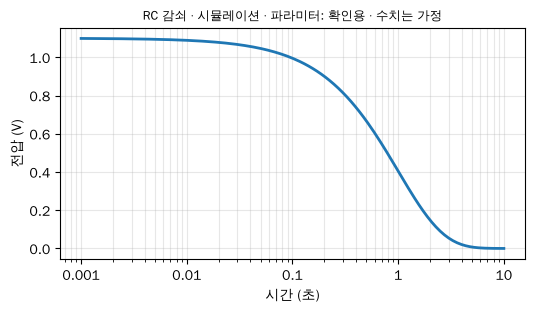

In [3]:
import matplotlib.pyplot as plt
import numpy as np
from memdev.plotting import plain_log_ticks, sim_label

t = np.logspace(-3, 1, 200)
fig, ax = plt.subplots(figsize=(6, 3))
ax.semilogx(t, 1.1 * np.exp(-t), lw=2)
plain_log_ticks(ax.xaxis)
ax.set_xlabel("시간 (초)")
ax.set_ylabel("전압 (V)")
ax.set_title("RC 감쇠 · " + sim_label("확인용"), fontsize=9)
ax.grid(alpha=0.3, which="both")
plt.show()

## 결과 요약

In [4]:
def mark(ok):
    return "통과" if ok else "실패"

print(f"{'항목':10s} | 결과")
print(f"{'ngspice':10s} | {mark(status['ngspice'])}")
print(f"{'ngspice RC':10s} | {mark(rc_ok)} ({t_fail:.4f} s, 기대 {expected:.4f} s)")
print(f"{'DEVSIM':10s} | {mark(status['devsim'])} (불러오기 확인, 접합 계산은 02 노트북)")
print(f"{'한글 폰트':10s} | {mark(status['korean_font'])}")

항목         | 결과
ngspice    | 통과
ngspice RC | 통과 (0.2578 s, 기대 0.2578 s)
DEVSIM     | 통과 (불러오기 확인, 접합 계산은 02 노트북)
한글 폰트      | 통과
